# Rejection-sampler cost against signal-to-noise

This notebook measures how the cost of the rejection sampler grows with the
signal-to-noise of the data, for the standard RV parameterization and the standard and
Thiele-Innes Gaia astrometry parameterizations, and makes the figure for the
performance appendix of the paper.

The cost of getting $X$ effective samples splits into two factors,
$$ t(X) \approx X \, \frac{J}{J_{\rm eff}} \, \frac{1}{R(N)} \quad , $$
where $R(N)$ is the number of prior samples evaluated per second, which depends on the
number of observations $N$ and the device but not on the data values, and
$J_{\rm eff}/J \approx e^{-H}$ (Case study 3), where $H$ is the information over the
sampled parameters. For informative data, each posterior width shrinks like
$1/\rho$, where $\rho$ is the total signal-to-noise ratio of the orbit over all $N$
observations (not the per-visit signal-to-noise ratio), so we expect
$J_{\rm eff}/J \propto \rho^{-d}$ with $d$ the number of sampled parameters: 4 for
the standard RV parameterization ($P$, $e$, phase, $\omega$) and 7 for the standard
Gaia parameterization ($P$, $e$, phase, $\omega$, $\Omega$, $\cos i$, and the
parallax, which is sampled because the prior on $a_0$ depends on it). The Thiele-Innes
parameterization replaces $a_0$ and the three orientation angles with four linear
constants, which leaves $d = 4$ ($P$, $e$, phase, and the parallax). If that is right,
curves for different $N$ fall on top of each other when plotted against $\rho$.

Run this on the benchmark workstation with a GPU (see `scripts/README.md`). On Linux,
the first cell pins the process to one CPU core, so the CPU throughput is for one core.
A full run takes a few hours; set `J_MAX = 10**6` for a quick check.

The results are saved to `data/benchmarks-ess.ecsv`. If that file exists, the notebook
skips the measurements and only makes the fits and the figure, so delete the file to
rerun them.

In [1]:
import os

# One CPU core for the CPU throughput numbers. This has to happen before numpy or jax
# are imported.
os.environ["XLA_FLAGS"] = (
    "--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1"
)
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[var] = "1"
if hasattr(os, "sched_setaffinity"):  # Linux only
    os.sched_setaffinity(0, {min(os.sched_getaffinity(0))})

import jax

# Enable float64 before importing harv:
jax.config.update("jax_enable_x64", True)

In [2]:
import time
import warnings
from pathlib import Path

import astropy.constants as const
import astropy.table as at
import astropy.units as u
import harv
import harv.models as hm
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from harv.models.parameterizations import ThieleInnesGaiaAstrometry
from harv.simulate import simulate_gaia_epoch_astrometry, simulate_rv_sb1_data
from unxt import Q

%matplotlib inline
print(f"harv {harv.__version__}, jax {jax.__version__}")
print(jax.devices())

# The sampler warns when J_eff < 3. Here that is expected for the largest rho values.
warnings.filterwarnings("ignore", message="Under-resolved rejection run")

harv 0.0.2.dev238+g4d7e5d20a, jax 0.11.2
[CpuDevice(id=0)]


In [3]:
repo_path = Path("..").resolve()
figure_path = repo_path / "paper" / "figures"
data_path = repo_path / "data"
figure_path.mkdir(exist_ok=True)
data_path.mkdir(exist_ok=True)

# The sweep and throughput results are saved here; delete the file to rerun them.
results_path = data_path / "benchmarks-ess.ecsv"
run_benchmarks = not results_path.exists()

J_MAX = 10**8  # largest prior library per source
ESS_MIN = 128  # J_eff needed to call a cell resolved
N_SEEDS = 3  # realizations of the observing times and noise per cell
RHO_VALUES = np.geomspace(10**-0.5, 1000.0, 15)  # total SNR, 0.25 dex apart
X = 1024  # effective samples per source, as in Case study 4

N_VALUES = {"rv": (3, 6, 12), "gaia": (40, 250), "gaia_ti": (40, 250)}
D_NL = {"rv": 4, "gaia": 7, "gaia_ti": 4}

## Priors and simulated data

We use the prior from Case study 1 for the RVs and the prior from Case study 2 for the
Gaia astrometry, without the jitter term. The parallax prior is a truncated normal
with a width of 1 mas around the true parallax, as in Case study 2, where it is
centered on the catalog value. The Thiele-Innes parameterization uses the same priors,
with a Gaussian prior on each Thiele-Innes constant that has the same period- and
parallax-dependent width as the prior on $a_0$. We do not apply the Jacobian
correction, so the implied prior on $a_0$ and the orientation of the orbit differs
from the standard one. Both Gaia parameterizations get the same simulated data.

Each data type has one fixed orbit. We change $\rho$ by scaling the uncertainties at
fixed $N$, and we draw new observing times and noise for each of `N_SEEDS`
realizations. RV: $P = 200$ days, $e = 0.3$, $K = 5~{\rm km\,s^{-1}}$ over 3 years.
Gaia: $P = 150$ days, $e = 0.2$ and $a_0 = 0.5$ mas over 5 years, with random scan
angles and parallax factors, for a Sun-like star at $G = 13$: $\varpi = 2.16$ mas from
the distance modulus with $M_{G,\odot} = 4.67$ and no extinction. The parallax matters
for the cost because the prior widths on $a_0$, the Thiele-Innes constants and the
proper motion scale with it. Both periods are near the logarithmic
middle of the period prior (181 and 141 days), so the edges of the prior do not
matter, and both orbits repeat many times over the baseline. The Gaia period is also
away from 1 year and its harmonics, where the orbit is partly degenerate with the
parallax, and from the 63-day precession period of the Gaia scanning law.

In [4]:
TI_NAMES = ("ti_A", "ti_B", "ti_F", "ti_G")
M_G_SUN = 4.67  # absolute G magnitude of the Sun


def parallax_for_G(G, M_G=M_G_SUN):
    """Parallax in mas at apparent magnitude G (distance modulus, no extinction)."""
    return 1e3 / 10 ** ((G - M_G) / 5 + 1)


PARALLAX = parallax_for_G(13.0)  # a Sun-like star at G = 13
rv_prior = hm.StandardRV().default_prior(
    period_min=Q(2.0, "day"),
    period_max=Q(16384.0, "day"),
    sigma_K0=Q(30.0, "km/s"),
    sigma_v0=Q(150.0, "km/s"),
    eccentricity=dist.TruncatedNormal(0.5, 0.25, low=0.0, high=1.0),
)
gaia_prior_kw = {
    "period_min": Q(10.0, "day"),
    "period_max": Q(2000.0, "day"),
    "sigma_a0": Q(1.0, "AU"),
    "sigma_pos": Q(100.0, "mas"),
    "sigma_vtan": Q(100.0, "km/s"),
    "parallax": harv.QD(dist.TruncatedNormal(PARALLAX, 1.0, low=0.0), "mas"),
}
gaia_prior = hm.StandardGaiaAstrometry().default_prior(**gaia_prior_kw)
thiele_innes = ThieleInnesGaiaAstrometry()  # no Jacobian correction
ti_prior = thiele_innes.default_prior(**gaia_prior_kw)
samplers = {
    "rv": harv.RejectionSampler(rv_prior, harv.RVModel()),
    "gaia": harv.RejectionSampler(
        gaia_prior,
        harv.GaiaAstrometryModel(),
        marginalized_names=("ra0", "dec0", "pmra", "pmdec", "semi_major_axis"),
    ),
    "gaia_ti": harv.RejectionSampler(
        ti_prior,
        harv.GaiaAstrometryModel(parameterization=thiele_innes),
        marginalized_names=("ra0", "dec0", "pmra", "pmdec", *TI_NAMES),
    ),
}

RV_TRUTH = {
    "period": Q(200.0, "day"),
    "eccentricity": 0.3,
    "time_peri": Q(50.0, "day"),
    "arg_peri": Q(1.0, "rad"),
    "rv_semiamp": Q(5.0, "km/s"),
    "v_sys": Q(0.0, "km/s"),
    "baseline": Q(3.0, "yr"),
}
GAIA_TRUTH = {
    "period": Q(150.0, "day"),
    "eccentricity": 0.2,
    "time_peri": Q(100.0, "day"),
    "arg_peri": Q(1.0, "rad"),
    "lon_asc_node": Q(2.0, "rad"),
    "inclination": Q(1.0, "rad"),
    "semi_major_axis": Q(0.5, "mas"),
    "parallax": Q(PARALLAX, "mas"),
    "mu_alpha": Q(5.0, "mas/yr"),
    "mu_delta": Q(-3.0, "mas/yr"),
    "baseline": Q(5.0, "yr"),
}


def simulate(kind, n_obs, err, seed):
    """Simulated data with uncertainty `err` (km/s for RV, mas for Gaia)."""
    if kind == "rv":
        data, _ = simulate_rv_sb1_data(
            seed=seed, n_obs=n_obs, rv_err=Q(err, "km/s"), **RV_TRUTH
        )
    else:
        data, _ = simulate_gaia_epoch_astrometry(
            seed=seed, n_obs=n_obs, al_error=Q(err, "mas"), **GAIA_TRUTH
        )
    return data

The total signal-to-noise ratio is the $\chi^2$ of the noiseless orbit signal after
fitting out the model without a companion (the systemic velocity for RVs; position,
proper motion and parallax for Gaia). It scales as $1/\sigma$, so we compute it once
for unit uncertainties, and then set $\sigma = \rho_1 / \rho$.

In [5]:
def rho_unit(kind, n_obs, seed):
    """Total signal-to-noise of the orbit for unit uncertainties."""
    data = simulate(kind, n_obs, 1e-30, seed)  # noiseless
    if kind == "rv":
        y = np.asarray(data.rv.to_value("km/s"))
        A = np.ones((n_obs, 1))
    else:
        y = np.asarray(data.al_position.to_value("mas"))
        psi = np.asarray(data.scan_angle.to_value("rad"))
        dt = np.asarray((data.time - data.time_ref).to_value("yr"))
        A = np.stack(
            [
                np.sin(psi),
                np.cos(psi),
                np.sin(psi) * dt,
                np.cos(psi) * dt,
                np.asarray(data.parallax_factor),
            ],
            axis=1,
        )
    resid = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    return np.sqrt(np.sum(resid**2))

## Representative companions

To relate the total SNR to real systems, we compute it for three companions: an M dwarf
($0.3~M_\odot$), a brown dwarf ($30~M_{\rm J}$) and a giant planet ($3~M_{\rm J}$). Each
is on the orbit of the sweep (all elements but the amplitude), so its cost can be read
off the curves. The RV host is a $1~M_\odot$ giant with $\sigma_v = 0.18~{\rm km\,s^{-1}}$
per visit, the median visit uncertainty of the six APOGEE stars in Case study 1, and the
mass is $m \sin i$. The Gaia host is the Sun-like star at $G = 13$ above, with
$\sigma_{\rm AL} = 0.03$ mas per transit, the median for Gaia-4 in Case study 2. The
companion is dark, so the photocenter orbit is $a_0 = a\,m/(M + m)\,\varpi$. The total
SNR scales as the amplitude over $\sigma$, so we rescale `rho_unit` from the sweep's orbit.

CHECK before the final run: $\sigma_{\rm AL}$ at $G = 13$ against the DR4 epoch
astrometry documentation, including whether DR4 epochs are per CCD or per transit.

In [6]:
COMPANIONS = {  # name: (mass, figure label)
    "M dwarf": (0.3 * u.Msun, r"$0.3\,M_\odot$"),
    "brown dwarf": (30 * u.Mjup, r"$30\,M_{\rm J}$"),
    "giant planet": (3 * u.Mjup, r"$3\,M_{\rm J}$"),
}
HOST_MASS = 1.0 * u.Msun
# Uncertainty per visit (km/s) for RV and per transit (mas) for Gaia:
SIGMA = {"rv": 0.18, "gaia": 0.03, "gaia_ti": 0.03}


def amplitude(kind, mass):
    """K in km/s (for m sin i = mass) or a_0 in mas (dark companion).

    All orbital elements but the amplitude are those of the sweep."""
    truth = RV_TRUTH if kind == "rv" else GAIA_TRUTH
    P = float(truth["period"].to_value("day")) * u.day
    M = HOST_MASS + mass
    if kind == "rv":
        e = truth["eccentricity"]
        K = (2 * np.pi * const.G / P) ** (1 / 3) * mass / M ** (2 / 3)
        return (K / np.sqrt(1 - e**2)).to_value(u.km / u.s)
    a = (const.G * M * P**2 / (4 * np.pi**2)) ** (1 / 3)
    return (a * mass / M).to_value(u.AU) * PARALLAX  # 1 AU at 1 mas parallax is 1 mas


def truth_amplitude(kind):
    if kind == "rv":
        return float(RV_TRUTH["rv_semiamp"].to_value("km/s"))
    return float(GAIA_TRUTH["semi_major_axis"].to_value("mas"))


companion_rho = {}  # total SNR over all N observations, for each N (median over seeds)
for kind in samplers:
    for name, (mass, _) in COMPANIONS.items():
        amp = amplitude(kind, mass)
        scale = amp / truth_amplitude(kind) / SIGMA[kind]
        companion_rho[kind, name] = np.array(
            [
                np.median([rho_unit(kind, n_obs, s) for s in range(N_SEEDS)]) * scale
                for n_obs in N_VALUES[kind]
            ]
        )
        per_obs = amp / SIGMA[kind]  # per-visit K/sigma_v or per-transit a_0/sigma_AL
        rho = np.round(companion_rho[kind, name], 2)
        print(
            f"{kind}, {name}: amplitude {amp:.3g} ({per_obs:.2g} sigma per "
            f"observation), total SNR {rho} for N = {N_VALUES[kind]}"
        )

# At G = 17 (a Sun-like star much farther away), the Gaia amplitudes shrink by:
print(f"parallax at G = 17 / G = 13: {parallax_for_G(17.0) / PARALLAX:.3f}")

rv, M dwarf: amplitude 9.61 (53 sigma per observation), total SNR [ 46.16  78.46 121.98] for N = (3, 6, 12)
rv, brown dwarf: amplitude 1.07 (6 sigma per observation), total SNR [ 5.15  8.76 13.61] for N = (3, 6, 12)
rv, giant planet: amplitude 0.109 (0.61 sigma per observation), total SNR [0.52 0.89 1.38] for N = (3, 6, 12)
gaia, M dwarf: amplitude 0.3 (10 sigma per observation), total SNR [33.69 87.25] for N = (40, 250)
gaia, brown dwarf: amplitude 0.0335 (1.1 sigma per observation), total SNR [3.76 9.74] for N = (40, 250)
gaia, giant planet: amplitude 0.00341 (0.11 sigma per observation), total SNR [0.38 0.99] for N = (40, 250)
gaia_ti, M dwarf: amplitude 0.3 (10 sigma per observation), total SNR [33.69 87.25] for N = (40, 250)
gaia_ti, brown dwarf: amplitude 0.0335 (1.1 sigma per observation), total SNR [3.76 9.74] for N = (40, 250)
gaia_ti, giant planet: amplitude 0.00341 (0.11 sigma per observation), total SNR [0.38 0.99] for N = (40, 250)
parallax at G = 17 / G = 13: 0.158


## Throughput

$R(N)$ for each data type and number of observations, on one CPU core and on the GPU
if there is one. The sampler draws the prior samples on the fly, which is how one
would run with $J = 10^8$.

In [7]:
devices = {"1 CPU core": jax.devices("cpu")[0]}
if jax.default_backend() == "gpu":
    devices["1 GPU"] = jax.devices()[0]
J_R = min(10**7, J_MAX)


def warm_time(sampler, data, J):
    """Wall time of one `run` call, after a first call that compiles."""
    key = jax.random.key(0)
    for _ in range(2):
        t0 = time.perf_counter()
        jax.block_until_ready(sampler.run(data, key=key, n_prior_samples=J, top_k=1))
    return time.perf_counter() - t0


if run_benchmarks:
    throughput = {}
    for name, device in devices.items():
        with jax.default_device(device):
            for kind, sampler in samplers.items():
                for n_obs in N_VALUES[kind]:
                    t = warm_time(sampler, simulate(kind, n_obs, 1.0, 0), J_R)
                    throughput[name, kind, n_obs] = J_R / t
                    print(f"{name}, {kind}, N = {n_obs}: {J_R / t / 1e6:.3g} M/s")

## The sweep

For each cell (a value of the total SNR $\rho$, $N$ and a realization), we run the sampler with $J = 10^6$ prior samples and multiply $J$ by 10
until $J_{\rm eff} \geq$ `ESS_MIN` or $J$ reaches `J_MAX`. Once a cell fails to
resolve, larger $\rho$ at the same $N$ and seed would fail too, so we stop there.

In [8]:
def measure(sampler, data, key):
    J = min(10**6, J_MAX)
    while True:
        s = sampler.run(data, key=key, n_prior_samples=J, top_k=1)
        ess = float(s.metadata["ln_Z_int_ess"])
        if ess >= ESS_MIN or J >= J_MAX:
            return J, ess
        J *= 10


if run_benchmarks:
    rows = []
    for kind, sampler in samplers.items():
        for n_obs in N_VALUES[kind]:
            for seed in range(N_SEEDS):
                rho1, key = rho_unit(kind, n_obs, seed), jax.random.key(seed)
                rho_fail = np.inf
                for rho in RHO_VALUES:
                    if rho >= rho_fail:  # known not to resolve
                        J, ess = J_MAX, np.nan
                    else:
                        data = simulate(kind, n_obs, rho1 / rho, seed)
                        J, ess = measure(sampler, data, key)
                        if ess < ESS_MIN:
                            rho_fail = rho
                    rows.append(
                        {
                            "kind": kind,
                            "N": n_obs,
                            "seed": seed,
                            "rho": rho,
                            "J": J,
                            "ess": ess,
                        }
                    )
                print(
                    f"{kind}, N = {n_obs}, seed {seed}: "
                    f"unresolved above total SNR = {rho_fail:.3g}"
                )

    res = at.Table(rows)
    res.meta["throughput"] = [[*key, R] for key, R in throughput.items()]
    res.write(results_path)
else:
    res = at.Table.read(results_path)
    throughput = {tuple(key): R for *key, R in res.meta["throughput"]}

res["ratio"] = res["ess"] / res["J"]
res["resolved"] = res["ess"] >= ESS_MIN  # NaN compares False
# The devices of the run, which can differ from the devices of this machine:
device_names = list(dict.fromkeys(name for name, _, _ in throughput))

## Results

We fit $\ln(J_{\rm eff}/J) = a + b \ln\rho$ to the resolved cells in the informative
regime ($J_{\rm eff}/J < 10^{-2}$), pooling all $N$ for each data type, and compare the
slope $b$ with $-d$. We also fit each $N$ separately to see whether the curves fall
on top of each other.

In [9]:
fits = {}
for kind in samplers:
    for n_obs in (None, *N_VALUES[kind]):
        m = (res["kind"] == kind) & res["resolved"] & (res["ratio"] < 1e-2)
        if n_obs is not None:
            m &= res["N"] == n_obs
        if m.sum() < 3:
            print(f"{kind}, N = {n_obs}: too few resolved cells to fit")
            continue
        b, a = np.polyfit(np.log(res["rho"][m]), np.log(res["ratio"][m]), 1)
        fits[kind, n_obs] = (a, b, np.exp(np.mean(np.log(res["rho"][m]))))
        print(f"{kind}, N = {n_obs or 'all'}: slope {b:.2f} (predicted {-D_NL[kind]})")


def predicted_ratio(kind, rho, n_obs=None):
    """J_eff/J from the fit for this N if there is one, else the fit to all N."""
    a, b, _ = fits.get((kind, n_obs), fits[kind, None])
    return np.exp(a) * rho**b


def sweep_curve(kind, n_obs):
    """Total SNR values where every realization resolved, and the prior samples needed
    for X effective samples there, with shape (rho, seed)."""
    sweep = res[(res["kind"] == kind) & (res["N"] == n_obs)]
    # ECSV does not round-trip every float exactly, so match rho with isclose:
    cells = [(r, np.isclose(sweep["rho"], r)) for r in RHO_VALUES]
    cells = [(r, m) for r, m in cells if m.any() and all(sweep["resolved"][m])]
    rhos = np.array([r for r, _ in cells])
    need = np.array([np.asarray(X / sweep["ratio"][m]) for _, m in cells])
    return rhos, need


print()
for kind in samplers:
    for name in COMPANIONS:
        for n_obs, rho in zip(N_VALUES[kind], companion_rho[kind, name], strict=True):
            rhos, need = sweep_curve(kind, n_obs)
            msg = f"{kind}, {name}, N = {n_obs}: total SNR {rho:.3g}"
            if len(rhos) and rhos[0] <= rho <= rhos[-1]:
                log_need = np.log(np.median(need, axis=1))
                J = np.exp(np.interp(np.log(rho), np.log(rhos), log_need))
                times = ", ".join(
                    f"{dev} {J / throughput[dev, kind, n_obs]:.3g} s"
                    for dev in device_names
                )
                msg += f", {J:.2g} prior samples for J_eff = {X} ({times})"
            elif len(rhos) and rho > rhos[-1]:
                msg += ", beyond the measured range"
            else:
                msg += ", below the sweep"
            print(msg)

rv, N = all: slope 0.36 (predicted -4)
rv, N = 3: slope -0.86 (predicted -4)
rv, N = 6: slope -3.13 (predicted -4)
rv, N = 12: slope -2.62 (predicted -4)
gaia, N = all: slope -4.12 (predicted -7)
gaia, N = 40: slope -3.93 (predicted -7)
gaia, N = 250: slope -4.72 (predicted -7)
gaia_ti, N = all: slope -2.26 (predicted -4)
gaia_ti, N = 40: slope -2.19 (predicted -4)
gaia_ti, N = 250: slope -2.35 (predicted -4)



ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (15,) + inhomogeneous part.

rv, N = 3: R / R(N = 6) = 0.92, 1 GPU / 1 CPU core = 81
rv, N = 6: R / R(N = 6) = 1.00, 1 GPU / 1 CPU core = 103
rv, N = 12: R / R(N = 6) = 0.80, 1 GPU / 1 CPU core = 102
gaia, N = 40: R / R(N = 100) = 1.62, 1 GPU / 1 CPU core = 155
gaia, N = 100: R / R(N = 100) = 1.00, 1 GPU / 1 CPU core = 155
gaia, N = 250: R / R(N = 100) = 0.48, 1 GPU / 1 CPU core = 141


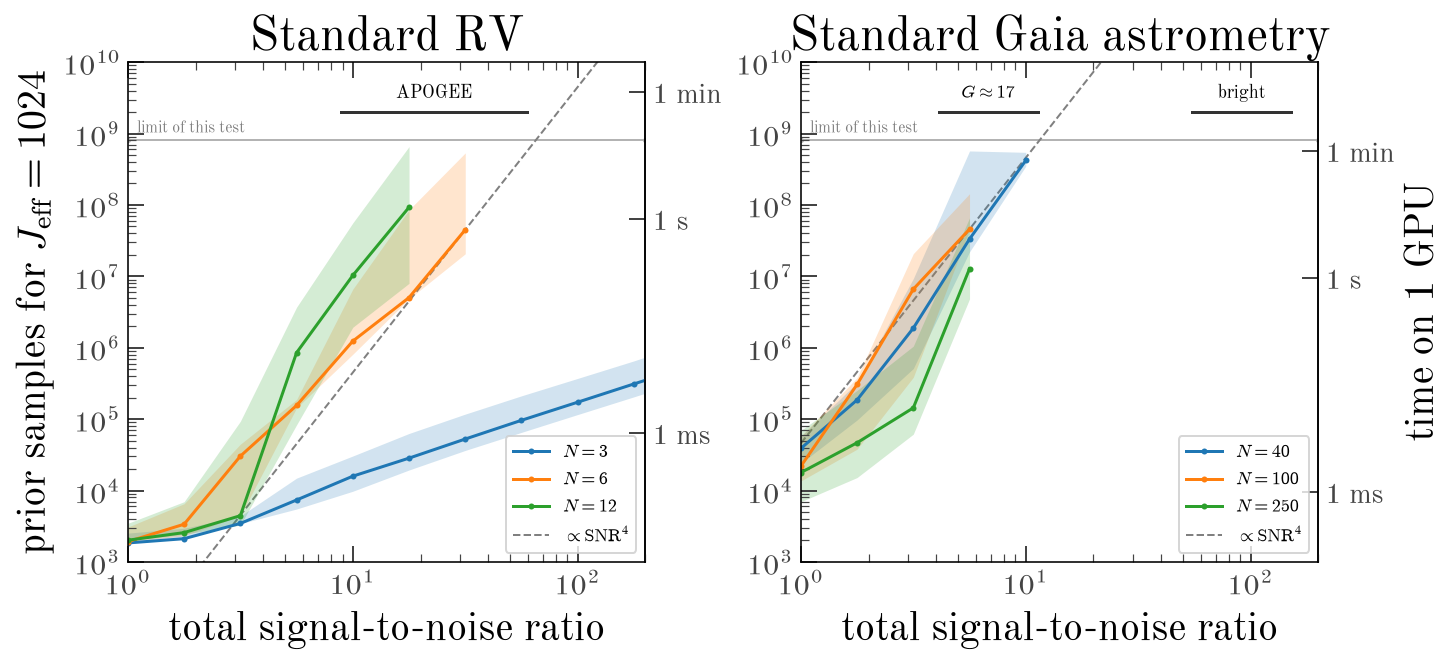

In [ ]:
colors = ("tab:blue", "tab:orange", "tab:green")
titles = {"rv": "Standard RV", "gaia": "Standard Gaia", "gaia_ti": "Thiele–Innes Gaia"}
xlabels = {
    "rv": r"total SNR ($\approx K/\sigma_K$)",
    "gaia": r"total SNR ($\approx a_0/\sigma_{a_0}$)",
    "gaia_ti": r"total SNR ($\approx a_0/\sigma_{a_0}$)",
}
rho_grid = np.geomspace(0.3, 200, 64)
# A resolved cell has J_eff >= ESS_MIN with J <= J_MAX, so no cell can show more than:
J_LIMIT = X * J_MAX / ESS_MIN

# The right axis converts prior samples to time on one device, using R(N) at the
# largest N. The other N differ by these factors:
device = "1 GPU" if "1 GPU" in device_names else "1 CPU core"
n_axis = {kind: n[-1] for kind, n in N_VALUES.items()}
for kind in samplers:
    for n_obs in N_VALUES[kind]:
        R = throughput[device, kind, n_obs]
        msg = f"{kind}, N = {n_obs}: R / R(N = {n_axis[kind]}) = "
        msg += f"{R / throughput[device, kind, n_axis[kind]]:.2f}"
        if device != "1 CPU core":
            R_cpu = throughput["1 CPU core", kind, n_obs]
            msg += f", {device} / 1 CPU core = {R / R_cpu:.0f}"
        print(msg)

fig, axes = plt.subplots(
    1, len(samplers), figsize=(14, 4.5), sharex=True, sharey=True, layout="constrained"
)
for ax, kind in zip(axes, samplers, strict=True):
    ax.set(xscale="log", yscale="log", xlim=(0.3, 200), ylim=(1e3, 1e10))
    ax.set(title=titles[kind], xlabel=xlabels[kind])

    for color, n_obs in zip(colors, N_VALUES[kind], strict=False):
        rhos, need = sweep_curve(kind, n_obs)
        ax.fill_between(
            rhos, need.min(axis=1), need.max(axis=1), color=color, alpha=0.2, lw=0
        )
        ax.plot(
            rhos,
            np.median(need, axis=1),
            marker="o",
            ms=3,
            color=color,
            label=f"$N = {n_obs}$",
        )
        if n_obs == n_axis[kind]:
            guide = np.median(need[-1]) * (rho_grid / rhos[-1]) ** 4

    ax.plot(
        rho_grid,
        guide,
        color="0.5",
        ls="--",
        lw=1,
        marker="",
        zorder=-1,
        label=r"$\propto$ (total SNR)$^4$",
    )
    ax.axhline(J_LIMIT, color="0.7", lw=1, zorder=-2)
    ax.text(
        0.33, J_LIMIT / 1.3, "limit of this test", fontsize=8, color="0.5", va="top"
    )

    # The total SNR of the representative companions, over the values of N:
    for name, (_, label) in COMPANIONS.items():
        rho = companion_rho[kind, name]
        ax.plot(
            [rho.min(), rho.max()],
            [0.9, 0.9],
            color="0.2",
            lw=1.5,
            marker="|",
            ms=6,
            transform=ax.get_xaxis_transform(),
        )
        ax.text(
            np.sqrt(rho.min() * rho.max()),
            0.92,
            label,
            ha="center",
            va="bottom",
            fontsize=9,
            transform=ax.get_xaxis_transform(),
        )

    ax.legend(loc="lower right", fontsize=9)
    R = throughput[device, kind, n_axis[kind]]
    ax.yaxis.set_ticks_position("left")
    sec = ax.secondary_yaxis(
        "right", functions=(lambda J, R=R: J / R, lambda t, R=R: t * R)
    )
    sec.set_yticks([1e-3, 1, 60, 3600], labels=["1 ms", "1 s", "1 min", "1 hr"])
    sec.yaxis.set_minor_locator(plt.NullLocator())

axes[0].set_ylabel(rf"prior samples for $J_{{\rm eff}} = {X}$")
sec.set_ylabel(f"time on {device}")
fig.savefig(figure_path / "bench-ess.pdf")